# AAL Australian Apparel Sales — Exploratory Data Analysis (Q4 2020)

**Course-end project · Applied Data Science with Python**

This notebook follows a structured exploratory-data-analysis workflow: define the business question, load and describe the data, profile data quality, clean and validate, explore the data with targeted questions, visualize patterns, and conclude with evidence-based recommendations.

> **How to use this notebook:** read each short explanation, run its code cell, and interpret the output before moving on. The analysis uses the CSV supplied with the assignment. It does not assume a currency because the source file does not label one.

## Table of Contents

1. [Problem Statement and Objectives](#section1)
2. [Data Loading and Description](#section2)
3. [Data Profiling Before Preprocessing](#section3)
4. [Data Preprocessing and Validation](#section4)
5. [Post-cleaning Profile and Normalization](#section5)
6. [Descriptive Statistics](#section6)
7. [Exploratory Data Analysis Questions](#section7)
   - [7.1 Which states generate the most and least sales?](#section71)
   - [7.2 How do customer groups compare?](#section72)
   - [7.3 Which state–customer-group combinations stand out?](#section73)
   - [7.4 Which time of day has the highest sales?](#section74)
   - [7.5 What do daily, weekly, monthly, and quarterly trends show?](#section75)
   - [7.6 What do distributions and box plots reveal?](#section76)
8. [Business Recommendations and Limitations](#section8)
9. [Conclusion](#section9)
10. [Exporting Tables for Submission](#section10)

<a id="section1"></a>
## 1. Problem Statement and Objectives

AAL is an apparel retailer operating across Australian states and territories. The sales and marketing team wants to understand Q4 2020 performance and identify practical opportunities for the next year.

### Questions this analysis should answer

- Which states have the highest and lowest recorded sales?
- How do Kids, Women, Men, and Seniors compare across states?
- Which of Morning, Afternoon, and Evening contributes the most recorded sales?
- What patterns appear in daily, weekly, monthly, and quarterly summaries?
- Are data-quality issues likely to affect conclusions?

### Required workflow

**Data wrangling → data analysis → data visualization → report and recommendations.** The goal is not to make charts for their own sake; every chart should help answer one of the business questions above.

<a id="section2"></a>
## 2. Data Loading and Description

### 2.1 Import the libraries

We use **Pandas** for tables and grouping, **NumPy** for numerical operations, and **Matplotlib/Seaborn** for charts. These libraries are sufficient for this task; no extra profiling package or installation is required.

In [1]:
%matplotlib inline
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

print("Libraries loaded successfully.")


Libraries loaded successfully.


### 2.2 Load the CSV dataset

Run the next code cell. If the CSV is already beside the notebook, it loads automatically. Otherwise, in Google Colab you can upload **either** `AusApparalSales4thQrt2020.csv` **or** the original ZIP supplied with the assignment. Use the supplied file; do not substitute a different dataset.


In [2]:
data_path = Path("AusApparalSales4thQrt2020.csv")

if data_path.exists():
    # Works when the CSV is already beside the notebook / in the Colab session.
    df_raw = pd.read_csv(data_path)
    print(f"Loaded file: {data_path.name}")
else:
    # In Google Colab, upload either the CSV or the ZIP supplied with the assignment.
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "CSV not found. Place AusApparalSales4thQrt2020.csv next to the notebook "
            "or run it in Colab and upload the CSV/ZIP."
        ) from exc

    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No file was uploaded.")

    selected_name = next(
        (name for name in uploaded if name.lower().endswith((".csv", ".zip"))),
        None
    )
    if selected_name is None:
        raise ValueError("Upload the assignment CSV or its ZIP file.")

    file_bytes = uploaded[selected_name]
    if selected_name.lower().endswith(".csv"):
        df_raw = pd.read_csv(BytesIO(file_bytes))
        print(f"Loaded CSV from upload: {selected_name}")
    else:
        with ZipFile(BytesIO(file_bytes)) as archive:
            csv_candidates = [
                name for name in archive.namelist()
                if name.lower().endswith(".csv") and not name.endswith("/")
            ]
            if not csv_candidates:
                raise ValueError("No CSV file was found inside the uploaded ZIP.")
            with archive.open(csv_candidates[0]) as csv_file:
                df_raw = pd.read_csv(csv_file)
            print(f"Loaded {csv_candidates[0]} from ZIP: {selected_name}")

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())


Loaded file: AusApparalSales4thQrt2020.csv
Rows: 7,560 | Columns: 6


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


### 2.3 Understand the columns

The dataset contains one row for a date, time-of-day category, state, and customer group. `Unit` is the number of units recorded; `Sales` is the corresponding sales value.

In [3]:
data_dictionary = pd.DataFrame({
    "Column": ["Date", "Time", "State", "Group", "Unit", "Sales"],
    "Meaning": [
        "Date of the sales record",
        "Time-of-day category: Morning, Afternoon, or Evening",
        "Australian state or territory code",
        "Customer group: Kids, Women, Men, or Seniors",
        "Number of units sold in the record",
        "Recorded sales value; source file does not specify currency"
    ],
    "Data type in source": df_raw.dtypes.astype(str).reindex(
        ["Date", "Time", "State", "Group", "Unit", "Sales"]
    ).values
})
display(data_dictionary)
print("First records:")
display(df_raw.head(8))
print("Last records:")
display(df_raw.tail(5))

,Column,Meaning,Data type in source
0,Date,Date of the sales record,object
1,Time,"Time-of-day category: Morning, Afternoon, or E...",object
2,State,Australian state or territory code,object
3,Group,"Customer group: Kids, Women, Men, or Seniors",object
4,Unit,Number of units sold in the record,int64
5,Sales,Recorded sales value; source file does not spe...,int64


First records:


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500
5,1-Oct-2020,Afternoon,WA,Men,10,25000
6,1-Oct-2020,Afternoon,WA,Women,3,7500
7,1-Oct-2020,Afternoon,WA,Seniors,11,27500


Last records:


,Date,Time,State,Group,Unit,Sales
7555,30-Dec-2020,Afternoon,TAS,Seniors,14,35000
7556,30-Dec-2020,Evening,TAS,Kids,15,37500
7557,30-Dec-2020,Evening,TAS,Men,15,37500
7558,30-Dec-2020,Evening,TAS,Women,11,27500
7559,30-Dec-2020,Evening,TAS,Seniors,13,32500


<a id="section3"></a>
## 3. Data Profiling Before Preprocessing

Before changing data, inspect its size, types, missing values, duplicates, and category values. This is the same principle as a pre-processing profile in a traditional EDA notebook: learn what is in the raw data before deciding what needs fixing.

### 3.1 Dataset structure

In [4]:
print("Dataset shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
df_raw.info()

Dataset shape: (7560, 6)

Column names:
['Date', 'Time', 'State', 'Group', 'Unit', 'Sales']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB


### 3.2 Missing values and duplicate records

`isna()` counts empty values. `duplicated()` finds rows repeated in every column. A quality check is useful even when it reports zero problems.

In [5]:
quality_before = pd.DataFrame({
    "Missing values": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2)
})
display(quality_before)
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))

,Missing values,Missing %
Date,0,0.00
Time,0,0.00
State,0,0.00
Group,0,0.00
Unit,0,0.00
Sales,0,0.00


Exact duplicate rows: 0


### 3.3 Category values and numeric ranges

The source contains leading spaces in some category names, such as `" VIC"` and `" Morning"`. They look similar to the clean values but are different strings to Python. We will remove the extra spaces in the cleaning stage.

In [6]:
for column in ["Time", "State", "Group"]:
    print(f"{column} values in raw source:")
    print([repr(value) for value in df_raw[column].dropna().unique()])
    print()

print("Numeric summary before preprocessing:")
display(df_raw[["Unit", "Sales"]].describe().T)

Time values in raw source:
["' Morning'", "' Afternoon'", "' Evening'"]

State values in raw source:
["' WA'", "' NT'", "' SA'", "' VIC'", "' QLD'", "' NSW'", "' TAS'"]

Group values in raw source:
["' Kids'", "' Men'", "' Women'", "' Seniors'"]

Numeric summary before preprocessing:


,count,mean,std,min,25%,50%,75%,max
Unit,"7,560.00",18.01,12.90,2.00,8.00,14.00,26.00,65.00
Sales,"7,560.00","45,013.56","32,253.51","5,000.00","20,000.00","35,000.00","65,000.00","162,500.00"


<a id="section4"></a>
## 4. Data Preprocessing and Validation

### 4.1 Cleaning decisions

- **Whitespace:** remove leading/trailing spaces from categorical values.
- **Date:** convert the source text into a true datetime value so it can be grouped by day, week, month, and quarter.
- **Numeric columns:** convert `Unit` and `Sales` to numeric values; invalid text becomes missing and must be reviewed.
- **Missing values:** inspect the amount and cause before choosing a treatment. In this dataset there are no blank source cells, so no imputation or row deletion is needed.
- **Duplicates and business rules:** check repeated rows, negative values, valid categories, record completeness, and whether sales follows the relationship seen in this source.

**Recommended treatment if an issue is found:** first correct an entry from the original source when possible. For a missing `Date`, `State`, `Group`, or `Time`, recover it from source records; do not guess a category just to fill the cell. For missing or invalid `Sales`/`Unit`, verify the source before considering imputation. If a value cannot be verified, compare the impact of excluding the affected row with any justified, documented imputation. Never replace missing sales with zero unless the source confirms there were genuinely zero sales. Treat negative values and sales-unit mismatches as exceptions to investigate, not as errors to delete automatically.

We keep the raw DataFrame (`df_raw`) unchanged and create a cleaned copy (`df`).


In [7]:
df = df_raw.copy()

# Standardize category text.
for column in ["Time", "State", "Group"]:
    df[column] = df[column].astype("string").str.strip()

# Convert the source format like 1-Oct-2020 into a datetime.
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%Y", errors="coerce")

# Convert numeric columns safely; invalid text becomes missing and is checked below.
for column in ["Unit", "Sales"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Data cleaned. Shape remains:", df.shape)
display(df.head())

Data cleaned. Shape remains: (7560, 6)


,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


### 4.2 Validate the cleaned data

A valid category must match one of the labels in the assignment. Sales and units should not be negative. The source also follows `Sales = Unit × 2,500` for every row; we use this as a dataset-specific consistency check, not as a universal retail rule. Since a complete day should contain one row for each of 3 time periods × 7 states/territories × 4 customer groups, we also check that each observed date has 84 records.


In [8]:
expected_values = {
    "Time": {"Morning", "Afternoon", "Evening"},
    "State": {"WA", "NT", "SA", "VIC", "QLD", "NSW", "TAS"},
    "Group": {"Kids", "Women", "Men", "Seniors"}
}

missing_after_cleaning = df.isna().sum()
invalid_categories = {
    column: sorted(set(df[column].dropna().unique()) - allowed)
    for column, allowed in expected_values.items()
}
negative_unit_rows = int((df["Unit"] < 0).sum())
negative_sales_rows = int((df["Sales"] < 0).sum())
unit_sales_rule_mismatches = int((df["Sales"] != df["Unit"] * 2500).sum())
logical_duplicate_rows = int(df.duplicated(subset=["Date", "Time", "State", "Group"]).sum())
expected_records_per_day = len(expected_values["Time"]) * len(expected_values["State"]) * len(expected_values["Group"])
records_per_observed_day = df.dropna(subset=["Date"]).groupby("Date").size()
incomplete_observed_dates = records_per_observed_day[records_per_observed_day != expected_records_per_day]

validation = pd.DataFrame({
    "Check": [
        "Missing cells after conversion",
        "Invalid category labels",
        "Negative Unit values",
        "Negative Sales values",
        "Duplicate Date-Time-State-Group combinations",
        "Sales != Unit × 2,500",
        "Observed dates with record count other than 84"
    ],
    "Result": [
        int(missing_after_cleaning.sum()),
        sum(len(items) for items in invalid_categories.values()),
        negative_unit_rows,
        negative_sales_rows,
        logical_duplicate_rows,
        unit_sales_rule_mismatches,
        len(incomplete_observed_dates)
    ]
})
display(validation)
print("Unexpected category values:", invalid_categories)
if not incomplete_observed_dates.empty:
    print("Observed dates with unexpected row counts:")
    display(incomplete_observed_dates.rename("Record count").to_frame())

if missing_after_cleaning.sum() > 0:
    print("Decision: investigate missing/invalid values before analysis; do not silently replace them.")
else:
    print("Decision: no missing cells remain after conversion, so imputation or dropping is not needed.")


,Check,Result
0,Missing cells after conversion,0
1,Invalid category labels,0
2,Negative Unit values,0
3,Negative Sales values,0
4,Duplicate Date-Time-State-Group combinations,0
5,"Sales != Unit × 2,500",0
6,Observed dates with record count other than 84,0


Unexpected category values: {'Time': [], 'State': [], 'Group': []}
Decision: no missing cells remain after conversion, so imputation or dropping is not needed.


### 4.3 Check expected date coverage

Q4 2020 runs from October 1 through December 31 (92 calendar days). A date with no records is **not** the same as a date with zero sales; it is a coverage gap to flag. The two dates without records will remain missing in daily summaries rather than being assigned zero sales.

In [9]:
expected_dates = pd.date_range("2020-10-01", "2020-12-31", freq="D")
present_dates = pd.DatetimeIndex(df["Date"].dropna().unique()).sort_values()
missing_dates = expected_dates.difference(present_dates)

print("Expected calendar days:", len(expected_dates))
print("Dates with records:", len(present_dates))
print("Dates without records:", len(missing_dates))
print("Missing dates:", [date.strftime("%Y-%m-%d") for date in missing_dates])
print("Observed date range:", df["Date"].min().date(), "to", df["Date"].max().date())

Expected calendar days: 92
Dates with records: 90
Dates without records: 2
Missing dates: ['2020-10-31', '2020-12-31']
Observed date range: 2020-10-01 to 2020-12-30


<a id="section5"></a>
## 5. Post-cleaning Profile and Normalization

### 5.1 Re-check quality after cleaning

In [10]:
profile_after = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique(dropna=True)
})
display(profile_after)
print("Exact duplicate rows after cleaning:", int(df.duplicated().sum()))
print("Clean state labels:", sorted(df["State"].dropna().unique()))
print("Clean group labels:", sorted(df["Group"].dropna().unique()))

,Data type,Missing values,Unique values
Date,datetime64[ns],0,90
Time,string,0,3
State,string,0,7
Group,string,0,4
Unit,int64,0,64
Sales,int64,0,64


Exact duplicate rows after cleaning: 0
Clean state labels: ['NSW', 'NT', 'QLD', 'SA', 'TAS', 'VIC', 'WA']
Clean group labels: ['Kids', 'Men', 'Seniors', 'Women']


### 5.2 Normalize numeric values using min-max normalization

Min-max normalization scales a numeric value to the range 0–1:

\[
 x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}
\]

We create new columns and preserve the original `Unit` and `Sales` columns. Normalized values are useful for comparing relative position on different scales, but they should not replace the original sales totals in business reporting.

In [11]:
df["Unit_normalized"] = (df["Unit"] - df["Unit"].min()) / (df["Unit"].max() - df["Unit"].min())
df["Sales_normalized"] = (df["Sales"] - df["Sales"].min()) / (df["Sales"].max() - df["Sales"].min())

display(df[["Unit", "Unit_normalized", "Sales", "Sales_normalized"]].head(10))
print("Normalized ranges:")
display(df[["Unit_normalized", "Sales_normalized"]].agg(["min", "max"]))

,Unit,Unit_normalized,Sales,Sales_normalized
0,8,0.10,20000,0.10
1,8,0.10,20000,0.10
2,4,0.03,10000,0.03
3,15,0.21,37500,0.21
4,3,0.02,7500,0.02
5,10,0.13,25000,0.13
6,3,0.02,7500,0.02
7,11,0.14,27500,0.14
8,15,0.21,37500,0.21
9,15,0.21,37500,0.21


Normalized ranges:


,Unit_normalized,Sales_normalized
min,0.00,0.00
max,1.00,1.00


### 5.3 Why `groupby()` is useful here

`groupby()` puts rows with the same label together, then calculates a result such as sum, mean, or count. It lets us answer “How much sales were recorded in each state?” without manually filtering each state. It also supports state-by-group, time-of-day, and reporting-period summaries.

**Recommendation:** use `groupby()` aggregation to produce the state, customer-group, time-of-day, and date-period summary tables from one consistent cleaned dataset. This reduces repetitive manual filtering and makes comparisons reproducible. Because the columns needed for these summaries are already in one table, merging separate tables is not necessary for the core analysis.


<a id="section6"></a>
## 6. Descriptive Statistics

Mean is the average, median is the middle value, mode is the most frequent value, and standard deviation describes spread around the mean. We calculate them for both required numeric columns: `Sales` and `Unit`.

### Why use Seaborn and Matplotlib?

**Seaborn is the recommended statistical-visualization package** for this report because it works naturally with Pandas DataFrames and provides clear box plots, distribution plots, and heatmaps with little code. **Matplotlib** complements it by giving direct control over titles, axes, labels, date ticks, and report layout. Together they cover the charts required in the assignment without adding unnecessary visualization libraries.


In [12]:
def first_mode(series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if not modes.empty else np.nan

stats = pd.DataFrame({
    "Mean": df[["Sales", "Unit"]].mean(),
    "Median": df[["Sales", "Unit"]].median(),
    "Mode": df[["Sales", "Unit"]].apply(first_mode),
    "Standard deviation": df[["Sales", "Unit"]].std(),
    "Minimum": df[["Sales", "Unit"]].min(),
    "Q1 (25%)": df[["Sales", "Unit"]].quantile(0.25),
    "Q3 (75%)": df[["Sales", "Unit"]].quantile(0.75),
    "Maximum": df[["Sales", "Unit"]].max()
})
display(stats.T)

print(f"Total recorded sales: {df['Sales'].sum():,.0f}")
print(f"Total recorded units: {df['Unit'].sum():,.0f}")
print(f"Average sales per row: {df['Sales'].mean():,.2f}")
print(f"Median sales per row: {df['Sales'].median():,.0f}")

,Sales,Unit
Mean,"45,013.56",18.01
Median,"35,000.00",14.00
Mode,"22,500.00",9.00
Standard deviation,"32,253.51",12.90
Minimum,"5,000.00",2.00
Q1 (25%),"20,000.00",8.00
Q3 (75%),"65,000.00",26.00
Maximum,"162,500.00",65.00


Total recorded sales: 340,302,500
Total recorded units: 136,121
Average sales per row: 45,013.56
Median sales per row: 35,000


<a id="section7"></a>
## 7. Exploratory Data Analysis Questions

This section mirrors a question-led EDA: each subsection asks one business question, calculates the necessary summary, visualizes it, and states what can reasonably be inferred.

<a id="section71"></a>
### 7.1 Which states generate the most and least sales?

We sum the sales and units for each state, then calculate each state's share of all recorded sales. Total sales show contribution to this dataset; they do not prove profitability or sales per store.

,State,Sales,Units,Records,Sales share (%)
5,VIC,105565000,42226,1080,31.02
0,NSW,74970000,29988,1080,22.03
3,SA,58857500,23543,1080,17.30
2,QLD,33417500,13367,1080,9.82
4,TAS,22760000,9104,1080,6.69
1,NT,22580000,9032,1080,6.64
6,WA,22152500,8861,1080,6.51


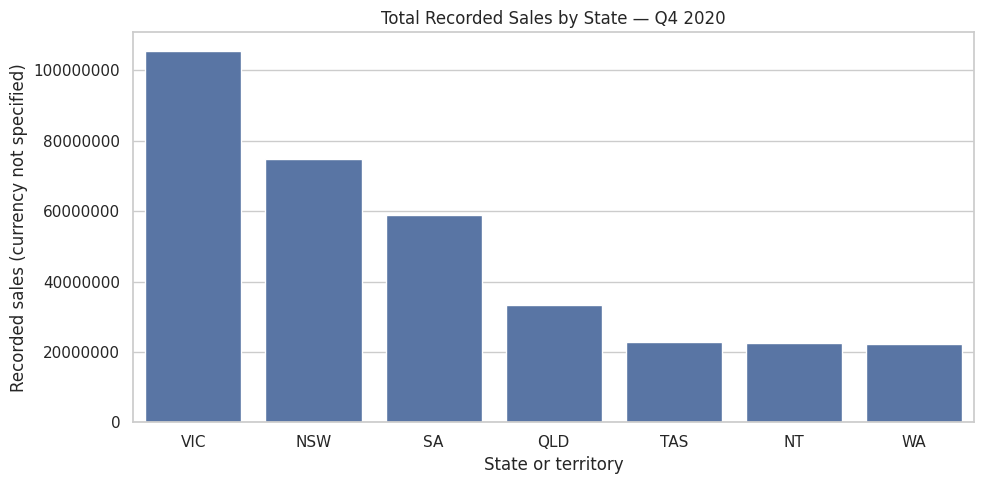

Highest-sales state: VIC (105,565,000)
Lowest-sales state: WA (22,152,500)


In [13]:
state_sales = (
    df.groupby("State", as_index=False)
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Records=("Sales", "size"))
      .sort_values("Sales", ascending=False)
)
state_sales["Sales share (%)"] = state_sales["Sales"] / df["Sales"].sum() * 100
display(state_sales)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=state_sales, x="State", y="Sales", order=state_sales["State"], color=sns.color_palette("deep")[0], ax=ax)
ax.set_title("Total Recorded Sales by State — Q4 2020")
ax.set_xlabel("State or territory")
ax.set_ylabel("Recorded sales (currency not specified)")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

print(f"Highest-sales state: {state_sales.iloc[0]['State']} ({state_sales.iloc[0]['Sales']:,.0f})")
print(f"Lowest-sales state: {state_sales.iloc[-1]['State']} ({state_sales.iloc[-1]['Sales']:,.0f})")

**Interpretation:** Read the bars from highest to lowest. The table gives exact totals and sales share. A lower state total is a reason to investigate local demand, store coverage, stock availability, and campaign activity—not enough evidence by itself to conclude the state is underperforming.

<a id="section72"></a>
### 7.2 How do customer groups compare?

The four groups are Kids, Women, Men, and Seniors. Compare their total sales first, then inspect the pattern inside each state.

,Group,Sales,Units
1,Men,85750000,34300
3,Women,85442500,34177
0,Kids,85072500,34029
2,Seniors,84037500,33615


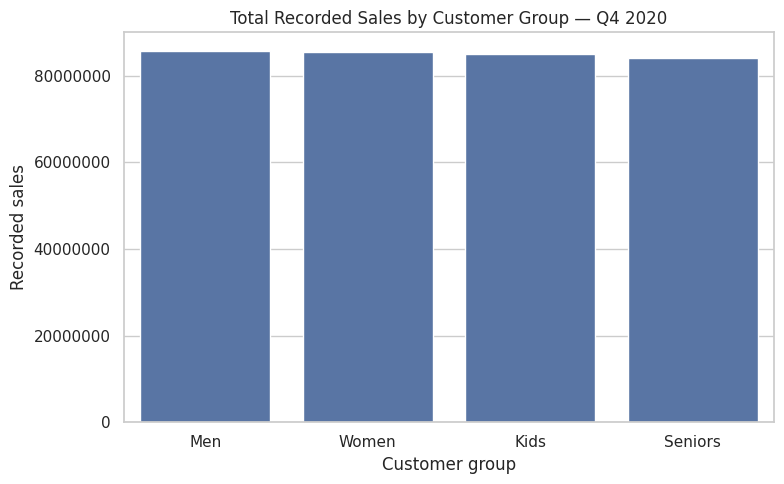

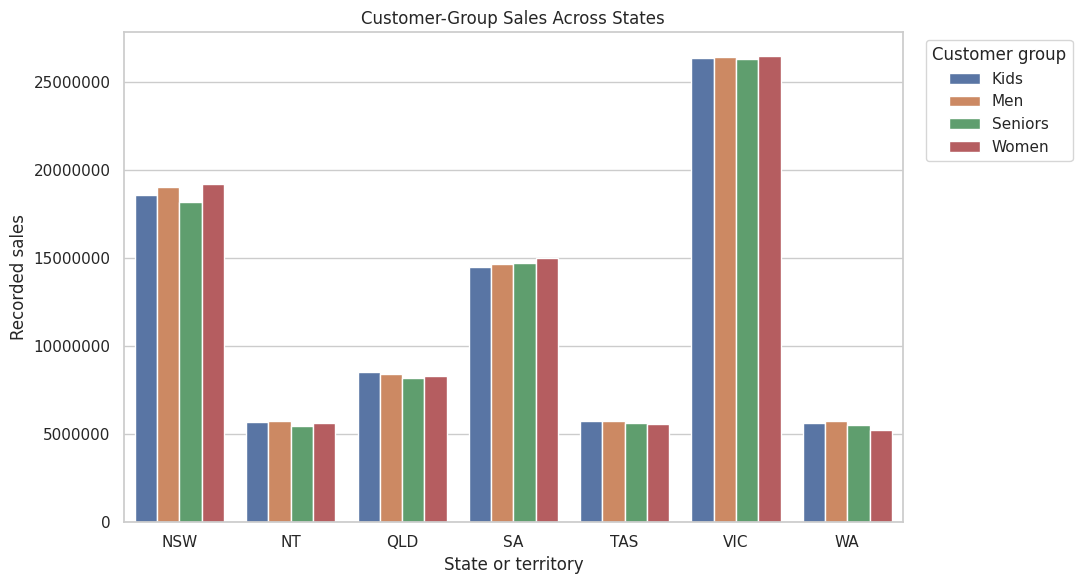

In [14]:
group_sales = (
    df.groupby("Group", as_index=False)
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"))
      .sort_values("Sales", ascending=False)
)
display(group_sales)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=group_sales, x="Group", y="Sales", order=group_sales["Group"], color=sns.color_palette("deep")[0], ax=ax)
ax.set_title("Total Recorded Sales by Customer Group — Q4 2020")
ax.set_xlabel("Customer group")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

state_group_sales = df.groupby(["State", "Group"], as_index=False)["Sales"].sum()
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=state_group_sales, x="State", y="Sales", hue="Group", palette="deep", ax=ax)
ax.set_title("Customer-Group Sales Across States")
ax.set_xlabel("State or territory")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
ax.legend(title="Customer group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### State-by-group heatmap

A heatmap makes it easier to compare which groups contribute more within each state. Darker/lighter color corresponds to different totals according to the legend; use the printed numbers as the exact values.

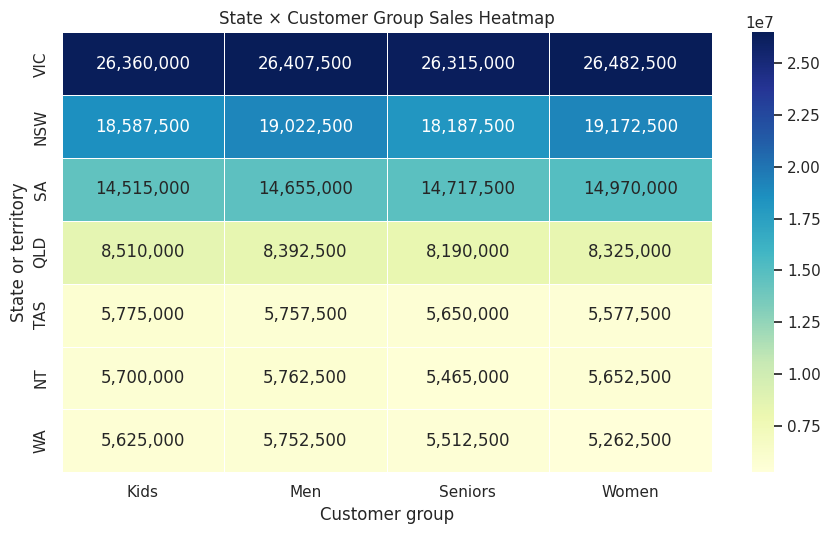

Group,Kids,Men,Seniors,Women
State,,,,
VIC,26360000,26407500,26315000,26482500
NSW,18587500,19022500,18187500,19172500
SA,14515000,14655000,14717500,14970000
QLD,8510000,8392500,8190000,8325000
TAS,5775000,5757500,5650000,5577500
NT,5700000,5762500,5465000,5652500
WA,5625000,5752500,5512500,5262500


In [15]:
state_group_pivot = df.pivot_table(
    index="State", columns="Group", values="Sales", aggfunc="sum"
).reindex(index=state_sales["State"].tolist())

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(state_group_pivot, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=0.5, ax=ax)
ax.set_title("State × Customer Group Sales Heatmap")
ax.set_xlabel("Customer group")
ax.set_ylabel("State or territory")
plt.tight_layout()
plt.show()

display(state_group_pivot)

<a id="section73"></a>
### 7.3 Which state–customer-group combinations stand out?

Ranking the combinations is useful for identifying segments to investigate. These are total sales in this quarter, not profit or an indication of customer lifetime value.

In [16]:
top_segments = state_group_sales.sort_values("Sales", ascending=False).head(10).reset_index(drop=True)
top_segments.insert(0, "Rank", np.arange(1, len(top_segments) + 1))
display(top_segments)

print("Lowest five recorded state–group totals:")
display(
    state_group_sales.sort_values("Sales", ascending=True)
      .head(5)
      .reset_index(drop=True)
)


,Rank,State,Group,Sales
0,1,VIC,Women,26482500
1,2,VIC,Men,26407500
2,3,VIC,Kids,26360000
3,4,VIC,Seniors,26315000
4,5,NSW,Women,19172500
5,6,NSW,Men,19022500
6,7,NSW,Kids,18587500
7,8,NSW,Seniors,18187500
8,9,SA,Women,14970000
9,10,SA,Seniors,14717500


Lowest five recorded state–group totals:


,State,Group,Sales
0,WA,Women,5262500
1,NT,Seniors,5465000
2,WA,Seniors,5512500
3,TAS,Women,5577500
4,WA,Kids,5625000


<a id="section74"></a>
### 7.4 Which time of day has the highest sales?

The `Time` column provides only three categories: Morning, Afternoon, and Evening. It does not contain exact clock times, so we should not make hour-by-hour claims.

,Time,Sales,Units
2,Morning,114207500,45683
0,Afternoon,114007500,45603
1,Evening,112087500,44835


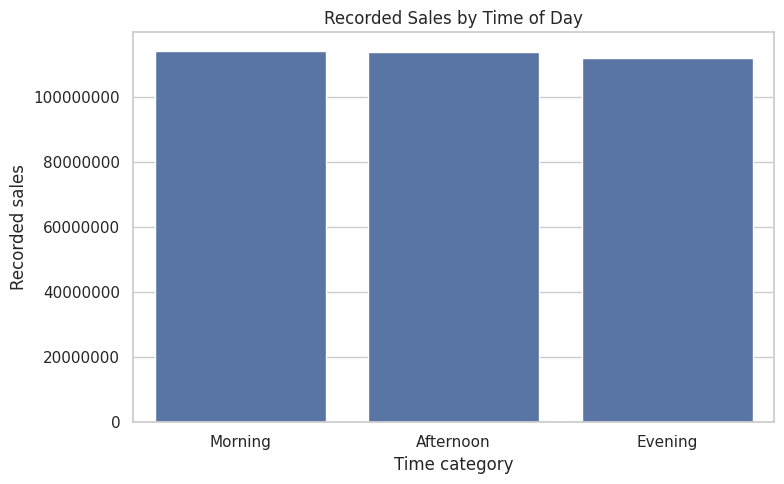

Highest-sales time category: Morning (114,207,500)


In [17]:
time_sales = (
    df.groupby("Time", as_index=False)
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"))
)
time_order = ["Morning", "Afternoon", "Evening"]
time_sales["Time"] = pd.Categorical(time_sales["Time"], categories=time_order, ordered=True)
time_sales = time_sales.sort_values("Time")
display(time_sales)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=time_sales, x="Time", y="Sales", order=time_order, color=sns.color_palette("deep")[0], ax=ax)
ax.set_title("Recorded Sales by Time of Day")
ax.set_xlabel("Time category")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

best_time = time_sales.sort_values("Sales", ascending=False).iloc[0]
print(f"Highest-sales time category: {best_time['Time']} ({best_time['Sales']:,.0f})")

<a id="section75"></a>
### 7.5 What do daily, weekly, monthly, and quarterly trends show?

We prepare reports at all four requested levels. Weeks start on Monday. Because October 31 and December 31 have no rows in the file, daily sales for those dates remain missing rather than being replaced with zero. The first and last weeks of the quarter may also be partial weeks.

#### Daily report

In [18]:
daily_report = (
    df.groupby("Date")
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Records=("Sales", "size"))
      .reindex(expected_dates)
)
daily_report.index.name = "Date"
# A count of 0 identifies days with no rows; Sales and Units remain NaN for those days.
daily_report["Records"] = daily_report["Records"].fillna(0).astype(int)
daily_report = daily_report.reset_index()

print("First 7 days:")
display(daily_report.head(7))
print("Dates with no sales records:")
display(daily_report[daily_report["Records"] == 0])
print("Last 7 days:")
display(daily_report.tail(7))

First 7 days:


,Date,Sales,Units,Records
0,2020-10-01,"3,720,000.00","1,488.00",84
1,2020-10-02,"3,715,000.00","1,486.00",84
2,2020-10-03,"3,890,000.00","1,556.00",84
3,2020-10-04,"3,720,000.00","1,488.00",84
4,2020-10-05,"3,862,500.00","1,545.00",84
5,2020-10-06,"3,960,000.00","1,584.00",84
6,2020-10-07,"3,712,500.00","1,485.00",84


Dates with no sales records:


,Date,Sales,Units,Records
30,2020-10-31,NaN,NaN,0
91,2020-12-31,NaN,NaN,0


Last 7 days:


,Date,Sales,Units,Records
85,2020-12-25,"4,390,000.00","1,756.00",84
86,2020-12-26,"4,715,000.00","1,886.00",84
87,2020-12-27,"4,637,500.00","1,855.00",84
88,2020-12-28,"4,595,000.00","1,838.00",84
89,2020-12-29,"4,607,500.00","1,843.00",84
90,2020-12-30,"4,590,000.00","1,836.00",84
91,2020-12-31,NaN,NaN,0


#### Daily sales chart

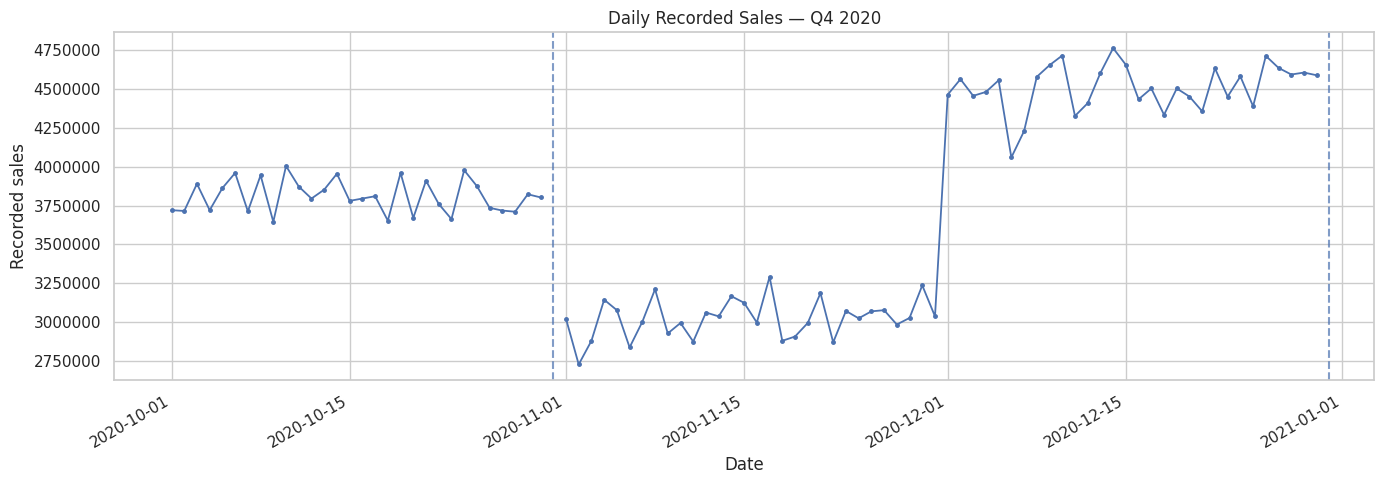

In [19]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_report["Date"], daily_report["Sales"], marker="o", markersize=2.5, linewidth=1.3)
for missing_date in missing_dates:
    ax.axvline(missing_date, linestyle="--", alpha=0.7)
ax.set_title("Daily Recorded Sales — Q4 2020")
ax.set_xlabel("Date")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### Weekly report and chart

,Week_Start,Sales,Units,Records,Observed_Days
0,2020-09-28,15045000,6018,336,4
1,2020-10-05,27002500,10801,588,7
2,2020-10-12,26640000,10656,588,7
3,2020-10-19,26815000,10726,588,7
4,2020-10-26,21807500,8723,504,6
5,2020-11-02,20865000,8346,588,7
6,2020-11-09,21172500,8469,588,7
7,2020-11-16,21112500,8445,588,7
8,2020-11-23,21477500,8591,588,7
9,2020-11-30,29622500,11849,588,7


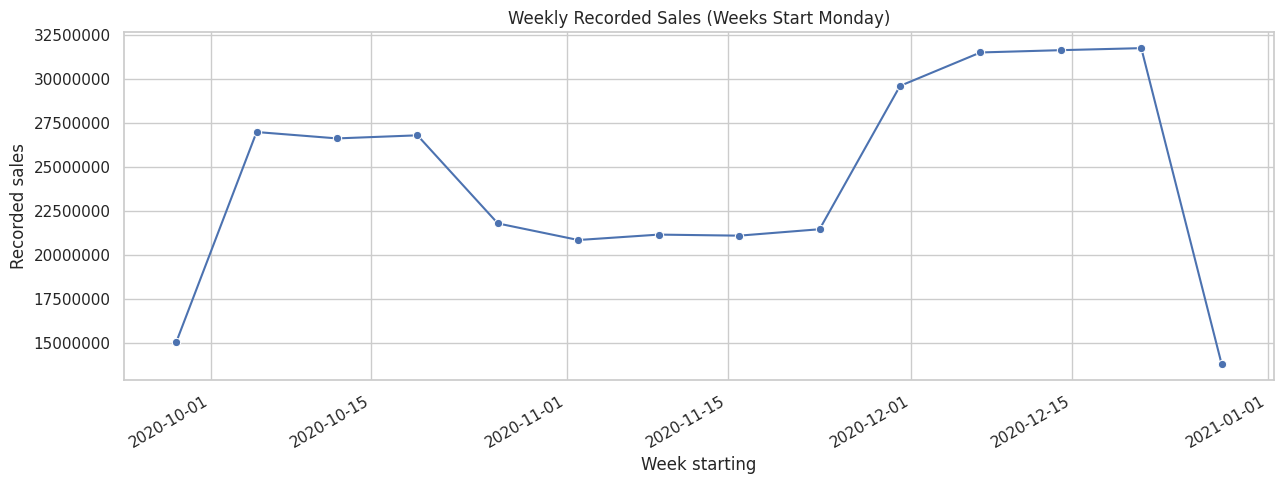

In [20]:
df["Week_Start"] = df["Date"] - pd.to_timedelta(df["Date"].dt.weekday, unit="D")
weekly_report = (
    df.groupby("Week_Start")
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Records=("Sales", "size"),
           Observed_Days=("Date", "nunique"))
      .reset_index()
      .sort_values("Week_Start")
)
display(weekly_report)

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=weekly_report, x="Week_Start", y="Sales", marker="o", ax=ax)
ax.set_title("Weekly Recorded Sales (Weeks Start Monday)")
ax.set_xlabel("Week starting")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### Monthly report and chart

,Month,Sales,Units,Records
0,2020-10,114290000,45716,2520
1,2020-11,90682500,36273,2520
2,2020-12,135330000,54132,2520


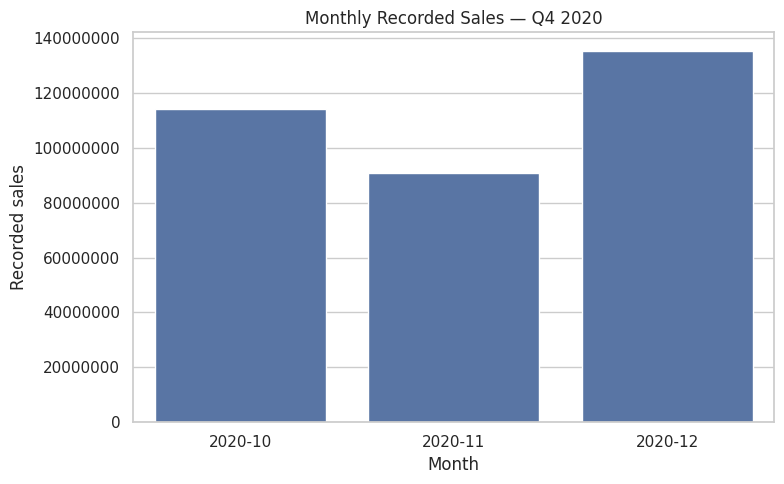

In [21]:
monthly_report = (
    df.assign(Month=df["Date"].dt.to_period("M").astype(str))
      .groupby("Month", as_index=False)
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Records=("Sales", "size"))
)
display(monthly_report)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=monthly_report, x="Month", y="Sales", color=sns.color_palette("deep")[0], ax=ax)
ax.set_title("Monthly Recorded Sales — Q4 2020")
ax.set_xlabel("Month")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

#### Quarterly report and chart

This source includes only Q4 2020. The quarterly chart therefore has one bar: it reports the quarter total but cannot compare one quarter with another.

,Quarter,Sales,Units,Records
0,2020Q4,340302500,136121,7560


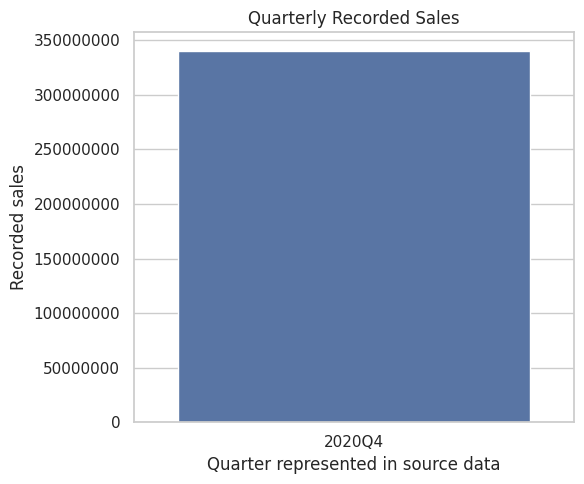

In [22]:
quarterly_report = (
    df.assign(Quarter=df["Date"].dt.to_period("Q").astype(str))
      .groupby("Quarter", as_index=False)
      .agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Records=("Sales", "size"))
)
display(quarterly_report)

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(data=quarterly_report, x="Quarter", y="Sales", color=sns.color_palette("deep")[0], ax=ax)
ax.set_title("Quarterly Recorded Sales")
ax.set_xlabel("Quarter represented in source data")
ax.set_ylabel("Recorded sales")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

<a id="section76"></a>
### 7.6 What do distributions and box plots reveal?

The distribution plots show where values occur most frequently. Box plots show the median, quartiles, spread, and potential outlying points. A potential outlier should be investigated; it is not automatically an error.

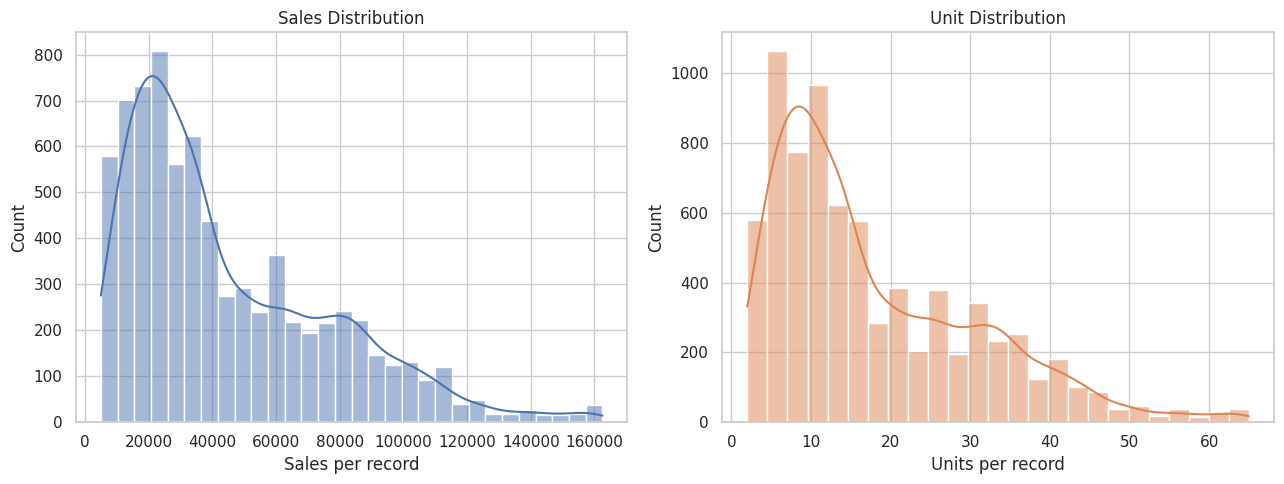

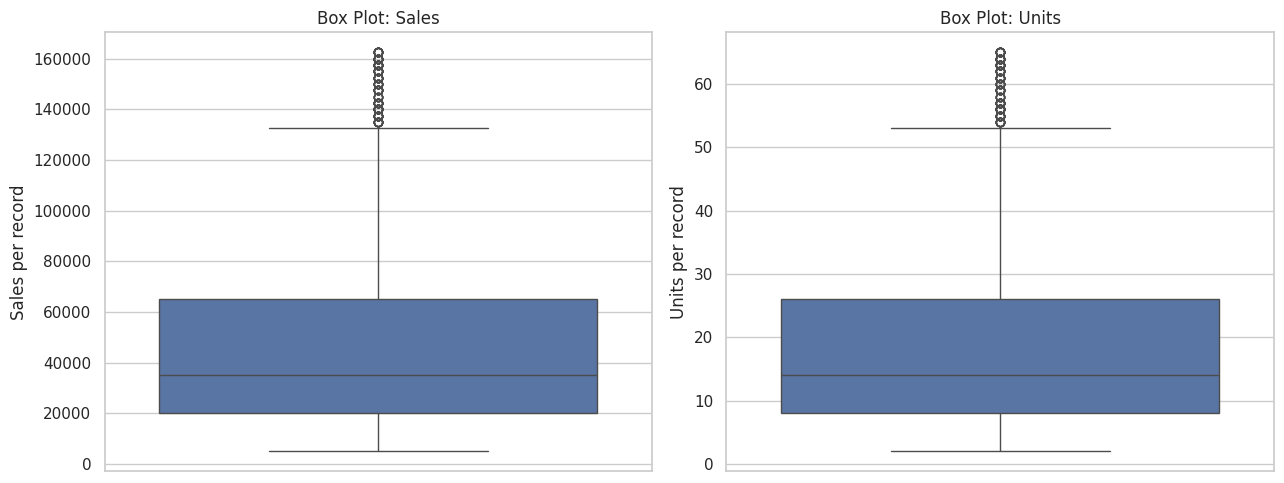

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["Sales"], bins=30, kde=True, color=sns.color_palette("deep")[0], ax=axes[0])
axes[0].set_title("Sales Distribution")
axes[0].set_xlabel("Sales per record")

sns.histplot(df["Unit"], bins=25, kde=True, color=sns.color_palette("deep")[1], ax=axes[1])
axes[1].set_title("Unit Distribution")
axes[1].set_xlabel("Units per record")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(y=df["Sales"], ax=axes[0])
axes[0].set_title("Box Plot: Sales")
axes[0].set_ylabel("Sales per record")

sns.boxplot(y=df["Unit"], ax=axes[1])
axes[1].set_title("Box Plot: Units")
axes[1].set_ylabel("Units per record")
plt.tight_layout()
plt.show()

<a id="section8"></a>
## 8. Business Recommendations and Limitations

### 8.1 Evidence-based findings

The next cell creates a compact set of findings from the calculated tables, rather than relying on numbers typed manually into Markdown. This helps prevent the narrative from drifting away from the data.

In [24]:
top_state = state_sales.iloc[0]
low_state = state_sales.iloc[-1]
top_group = group_sales.sort_values("Sales", ascending=False).iloc[0]
low_group = group_sales.sort_values("Sales", ascending=True).iloc[0]
top_time_row = time_sales.sort_values("Sales", ascending=False).iloc[0]
top_month = monthly_report.sort_values("Sales", ascending=False).iloc[0]
top_segment = state_group_sales.sort_values("Sales", ascending=False).iloc[0]
low_segment = state_group_sales.sort_values("Sales", ascending=True).iloc[0]

total_sales = df["Sales"].sum()
print("KEY FINDINGS")
print(f"• Total recorded sales: {total_sales:,.0f}")
print(f"• Highest-sales state: {top_state['State']} ({top_state['Sales']:,.0f})")
print(f"• Lowest-sales state: {low_state['State']} ({low_state['Sales']:,.0f})")
print(f"• Highest-sales group: {top_group['Group']} ({top_group['Sales']:,.0f})")
print(f"• Lowest-sales group: {low_group['Group']} ({low_group['Sales']:,.0f})")
print(f"• Highest-sales time category: {top_time_row['Time']} ({top_time_row['Sales']:,.0f})")
print(f"• Highest-sales month by recorded total: {top_month['Month']} ({top_month['Sales']:,.0f})")
print(f"• Highest state-group total: {top_segment['State']} / {top_segment['Group']} ({top_segment['Sales']:,.0f})")
print(f"• Lowest state-group total: {low_segment['State']} / {low_segment['Group']} ({low_segment['Sales']:,.0f})")

KEY FINDINGS
• Total recorded sales: 340,302,500
• Highest-sales state: VIC (105,565,000)
• Lowest-sales state: WA (22,152,500)
• Highest-sales group: Men (85,750,000)
• Lowest-sales group: Seniors (84,037,500)
• Highest-sales time category: Morning (114,207,500)
• Highest-sales month by recorded total: 2020-12 (135,330,000)
• Highest state-group total: VIC / Women (26,482,500)
• Lowest state-group total: WA / Women (5,262,500)


### 8.2 Recommendations

1. **Investigate lower-total states before spending more:** compare the state sales totals with number of stores, stock availability, local customer demand, and marketing expenditure. The CSV does not include these factors, so it cannot explain the cause of a low total.
2. **Use targeted tests instead of broad assumptions:** use the state-by-group heatmap to choose a small set of audience and location combinations for test campaigns. Compare results with a control period before expanding.
3. **Test time-of-day offers carefully:** sales totals across Morning, Afternoon, and Evening are close. Run a controlled evening promotion and compare it with similar days rather than presuming that Evening is weak.
4. **Plan around the observed monthly pattern:** December has the largest recorded monthly total in this file. Since two dates have no records, verify data completeness before making staffing or inventory decisions.
5. **Protect data quality:** confirm why October 31 and December 31 have no records and keep a repeatable validation step in future reporting.

### 8.3 Limitations

- The file covers one quarter only; it cannot establish year-over-year or multi-quarter growth.
- The two dates without records may reflect missing data rather than zero sales.
- Sales currency is not labelled in the CSV.
- Store counts, marketing costs, inventory, profit, and customer-level details are not provided. Revenue totals alone cannot establish profitability, ROI, or a causal reason for sales differences.
- Time is available only as three broad periods, not exact hours.

<a id="section9"></a>
## 9. Conclusion

This notebook completes the AAL project's core workflow: load the sales dataset, profile its quality, clean categories and dates, validate values, normalize numeric columns, calculate descriptive statistics, analyze state/group/time patterns, create daily/weekly/monthly/quarterly reports, visualize distributions, and produce business recommendations.

The central discipline is to **separate observed results from explanations**. The tables show what was recorded in Q4 2020. Additional store, cost, and customer information would be needed to explain why the pattern occurred and whether an expansion is financially justified.

<a id="section10"></a>
## 10. Exporting Tables for Submission

This final optional step saves key summary tables as CSV files. Keep the notebook and these exports together if your lecturer asks for the supporting analysis tables. In Colab, outputs are saved in the session's working directory.

In [25]:
export_tables = {
    "aal_state_sales_summary.csv": state_sales,
    "aal_group_sales_summary.csv": group_sales,
    "aal_daily_sales_report.csv": daily_report,
    "aal_weekly_sales_report.csv": weekly_report,
    "aal_monthly_sales_report.csv": monthly_report,
    "aal_quarterly_sales_report.csv": quarterly_report,
    "aal_state_group_sales.csv": state_group_sales,
    "aal_descriptive_statistics.csv": stats
}

for filename, table in export_tables.items():
    table.to_csv(filename, index=False)
    print("Saved:", filename)

print("\nProject analysis completed.")

Saved: aal_state_sales_summary.csv
Saved: aal_group_sales_summary.csv
Saved: aal_daily_sales_report.csv
Saved: aal_weekly_sales_report.csv
Saved: aal_monthly_sales_report.csv
Saved: aal_quarterly_sales_report.csv
Saved: aal_state_group_sales.csv
Saved: aal_descriptive_statistics.csv

Project analysis completed.
